# Chapter 4 Simulation: Coordinate-Free $SE(3) \times S^2$ Quadrotor–Load Dynamics

This notebook accompanies **Chapter 4** (*Coordinate-Free Dynamics: Riemannian Mechanics, Lagrange–d'Alembert & Multi-Body Formulations*) of *A Lie-Interpretation of Robotics and Control*.

We implement a **Lie-group RK4 integrator** for the taut-mode ($\Sigma_n$) quadrotor with cable-suspended load on $SE(3) \times S^2$ ([Sreenath, Lee, & Kumar, CDC 2013](https://hybrid-robotics.berkeley.edu/publications/CDC2013.pdf)) and verify:
1. **Unforced total mechanical energy conservation** ($E(t) = T(t) + U(t) = E(0)$ when $f = 0, M = 0$).
2. **Manifold invariance** ($\|q(t)\| = 1$ on $S^2$, $\omega(t) \cdot q(t) = 0$, and $R(t)^T R(t) = I$ on $SO(3)$).
3. **Forced swing & cable tension monitoring** ($T(t) = \|m_L(\dot{v}_L + g e_3)\|$) with comparison against naive Euler integration.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def hat(x):
    return np.array([
        [0.0, -x[2], x[1]],
        [x[2], 0.0, -x[0]],
        [-x[1], x[0], 0.0]
    ])

def vee(S):
    return np.array([S[2, 1], S[0, 2], S[1, 0]])

def exp_so3(phi):
    theta = np.linalg.norm(phi)
    K = hat(phi)
    if theta < 1e-8:
        return np.eye(3) + K + 0.5 * (K @ K)
    return np.eye(3) + (np.sin(theta) / theta) * K + ((1.0 - np.cos(theta)) / (theta ** 2)) * (K @ K)

print("Lie-algebraic operators initialized.")

Lie-algebraic operators initialized.


In [2]:
# System parameters (Sreenath, Lee, & Kumar, CDC 2013)
mQ = 0.85   # quadrotor mass (kg)
mL = 0.25   # load mass (kg)
l = 1.0     # cable length (m)
g = 9.81    # gravity (m/s^2)
e3 = np.array([0.0, 0.0, 1.0])
JQ = np.diag([0.00557, 0.00557, 0.0105])
JQ_inv = np.linalg.inv(JQ)

def total_energy(xL, vL, q, omega, R, Omega):
    q_dot = np.cross(omega, q)
    vQ = vL - l * q_dot
    xQ = xL - l * q
    T = 0.5 * mQ * np.dot(vQ, vQ) + 0.5 * mL * np.dot(vL, vL) + 0.5 * np.dot(Omega, JQ @ Omega)
    U = mQ * g * np.dot(e3, xQ) + mL * g * np.dot(e3, xL)
    return T + U, T, U

def rhs_se3_s2(xL, vL, q, omega, R, Omega, f, M):
    q_dot = np.cross(omega, q)
    thrust_vec = f * (R @ e3)
    vL_dot = -g * e3 + ((np.dot(q, thrust_vec) - mQ * l * np.dot(q_dot, q_dot)) / (mQ + mL)) * q
    omega_dot = -np.cross(q, thrust_vec) / (mQ * l)
    Omega_dot = JQ_inv @ (M - np.cross(Omega, JQ @ Omega))
    return vL, vL_dot, omega_dot, Omega_dot

def step_lie_rk4(xL, vL, q, omega, R, Omega, f, M, dt):
    # Stage 1
    dx1, dv1, dw1, dW1 = rhs_se3_s2(xL, vL, q, omega, R, Omega, f, M)
    w_s1, W_s1 = omega, Omega

    # Stage 2
    x2 = xL + 0.5 * dt * dx1
    v2 = vL + 0.5 * dt * dv1
    w2 = omega + 0.5 * dt * dw1
    W2 = Omega + 0.5 * dt * dW1
    q2 = exp_so3(0.5 * dt * w_s1) @ q
    R2 = R @ exp_so3(0.5 * dt * W_s1)
    dx2, dv2, dw2, dW2 = rhs_se3_s2(x2, v2, q2, w2, R2, W2, f, M)

    # Stage 3
    x3 = xL + 0.5 * dt * dx2
    v3 = vL + 0.5 * dt * dv2
    w3 = omega + 0.5 * dt * dw2
    W3 = Omega + 0.5 * dt * dW2
    q3 = exp_so3(0.5 * dt * w2) @ q
    R3 = R @ exp_so3(0.5 * dt * W2)
    dx3, dv3, dw3, dW3 = rhs_se3_s2(x3, v3, q3, w3, R3, W3, f, M)

    # Stage 4
    x4 = xL + dt * dx3
    v4 = vL + dt * dv3
    w4 = omega + dt * dw3
    W4 = Omega + dt * dW3
    q4 = exp_so3(dt * w3) @ q
    R4 = R @ exp_so3(dt * W3)
    dx4, dv4, dw4, dW4 = rhs_se3_s2(x4, v4, q4, w4, R4, W4, f, M)

    # Combine
    xL_next = xL + (dt / 6.0) * (dx1 + 2*dx2 + 2*dx3 + dx4)
    vL_next = vL + (dt / 6.0) * (dv1 + 2*dv2 + 2*dv3 + dv4)
    omega_next = omega + (dt / 6.0) * (dw1 + 2*dw2 + 2*dw3 + dw4)
    Omega_next = Omega + (dt / 6.0) * (dW1 + 2*dW2 + 2*dW3 + dW4)
    q_next = exp_so3((dt / 6.0) * (w_s1 + 2*w2 + 2*w3 + w4)) @ q
    R_next = R @ exp_so3((dt / 6.0) * (W_s1 + 2*W2 + 2*W3 + W4))
    return xL_next, vL_next, q_next, omega_next, R_next, Omega_next

print("Dynamics and Lie-RK4 integrator defined.")

Dynamics and Lie-RK4 integrator defined.


In [3]:
# Test 1: Unforced conservation (f = 0, M = 0) over 5 seconds
dt = 0.005
N = int(5.0 / dt)
t_arr = np.arange(N + 1) * dt

xL = np.array([0.0, 0.0, 10.0])
vL = np.array([0.5, -0.3, 2.0])
q = np.array([np.sin(0.4), 0.0, -np.cos(0.4)])
q = q / np.linalg.norm(q)
omega = np.cross(q, np.array([0.0, 1.2, 0.3]))  # ensures omega . q = 0
R = exp_so3(np.array([0.2, -0.1, 0.3]))
Omega = np.array([0.8, -0.5, 1.1])

E_hist = np.zeros(N + 1)
q_norm_err = np.zeros(N + 1)
ortho_err = np.zeros(N + 1)
R_orth_err = np.zeros(N + 1)

# Also run naive Euler for comparison
xL_e, vL_e, q_e, w_e, R_e, W_e = xL.copy(), vL.copy(), q.copy(), omega.copy(), R.copy(), Omega.copy()
E_euler = np.zeros(N + 1)
q_norm_euler = np.zeros(N + 1)

for k in range(N + 1):
    E_hist[k], _, _ = total_energy(xL, vL, q, omega, R, Omega)
    q_norm_err[k] = abs(np.linalg.norm(q) - 1.0)
    ortho_err[k] = abs(np.dot(omega, q))
    R_orth_err[k] = np.linalg.norm(R.T @ R - np.eye(3), ord='fro')

    E_euler[k], _, _ = total_energy(xL_e, vL_e, q_e, w_e, R_e, W_e)
    q_norm_euler[k] = abs(np.linalg.norm(q_e) - 1.0)

    if k < N:
        xL, vL, q, omega, R, Omega = step_lie_rk4(xL, vL, q, omega, R, Omega, 0.0, np.zeros(3), dt)
        # Naive Euler step
        dx, dv, dw, dW = rhs_se3_s2(xL_e, vL_e, q_e, w_e, R_e, W_e, 0.0, np.zeros(3))
        q_e = q_e + dt * np.cross(w_e, q_e)
        R_e = R_e + dt * (R_e @ hat(W_e))
        xL_e, vL_e, w_e, W_e = xL_e + dt*dx, vL_e + dt*dv, w_e + dt*dw, W_e + dt*dW

E0 = E_hist[0]
rel_E_drift = np.max(np.abs(E_hist - E0)) / abs(E0)
rel_E_drift_euler = np.max(np.abs(E_euler - E0)) / abs(E0)

print(f"Initial Energy E0:              {E0:.6f} J")
print(f"Final Energy (Lie-RK4):         {E_hist[-1]:.6f} J")
print(f"Max Relative Energy Drift (RK4):{rel_E_drift:.3e}")
print(f"Max Relative Energy Drift (Eul):{rel_E_drift_euler:.3e}")
print(f"Max | ||q|| - 1 | (Lie-RK4):    {np.max(q_norm_err):.3e}")
print(f"Max | ||q|| - 1 | (Euler):      {np.max(q_norm_euler):.3e}")
print(f"Max |omega . q| (Lie-RK4):      {np.max(ortho_err):.3e}")
print(f"Max ||R^T R - I||_F (Lie-RK4):  {np.max(R_orth_err):.3e}")

Initial Energy E0:              118.786827 J
Final Energy (Lie-RK4):         118.786827 J
Max Relative Energy Drift (RK4):1.908e-13
Max Relative Energy Drift (Eul):1.614e-02
Max | ||q|| - 1 | (Lie-RK4):    3.753e-14
Max | ||q|| - 1 | (Euler):      1.834e-02
Max |omega . q| (Lie-RK4):      8.234e-15
Max ||R^T R - I||_F (Lie-RK4):  4.470e-14


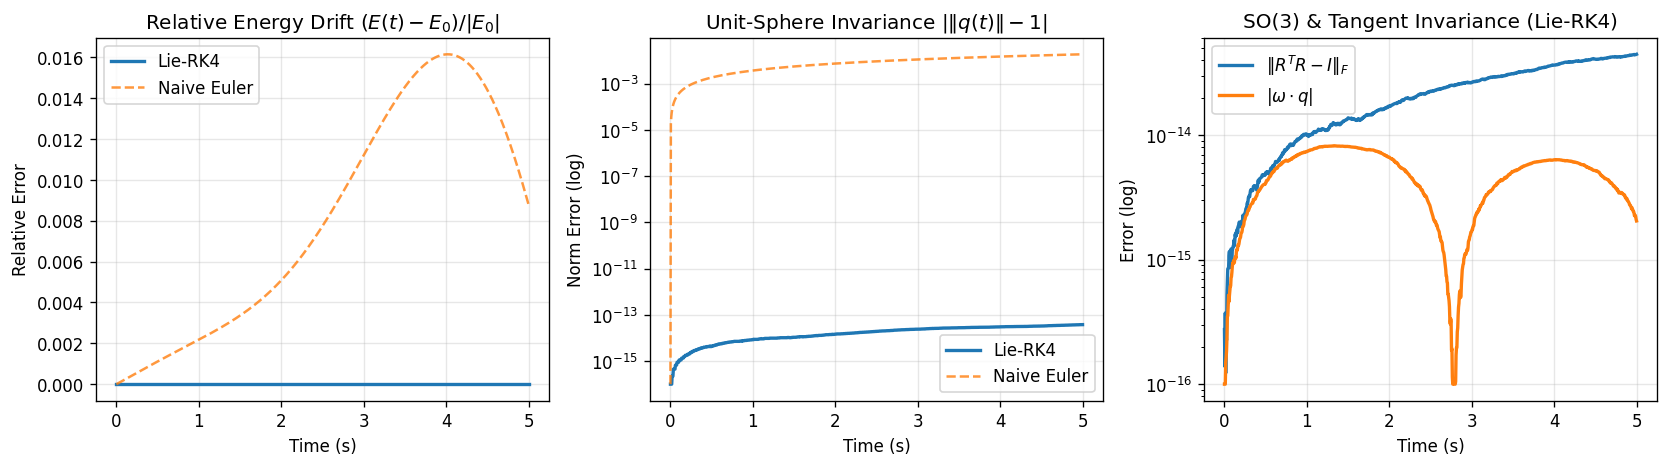

In [4]:
# Plot conservation and manifold invariance metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(t_arr, (E_hist - E0) / abs(E0), label='Lie-RK4', lw=2)
axes[0].plot(t_arr, (E_euler - E0) / abs(E0), '--', label='Naive Euler', alpha=0.8)
axes[0].set_title('Relative Energy Drift $(E(t) - E_0)/|E_0|$')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Relative Error')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].semilogy(t_arr, np.maximum(q_norm_err, 1e-16), label='Lie-RK4', lw=2)
axes[1].semilogy(t_arr, np.maximum(q_norm_euler, 1e-16), '--', label='Naive Euler', alpha=0.8)
axes[1].set_title('Unit-Sphere Invariance $|\|q(t)\| - 1|$')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Norm Error (log)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].semilogy(t_arr, np.maximum(R_orth_err, 1e-16), label='$\|R^T R - I\|_F$', lw=2)
axes[2].semilogy(t_arr, np.maximum(ortho_err, 1e-16), label='$|\omega \cdot q|$', lw=2)
axes[2].set_title('SO(3) & Tangent Invariance (Lie-RK4)')
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Error (log)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Min Cable Tension (Hover Swing): 2.1239 N (T > 0 => remains taut)
Max Cable Tension (Hover Swing): 3.1096 N


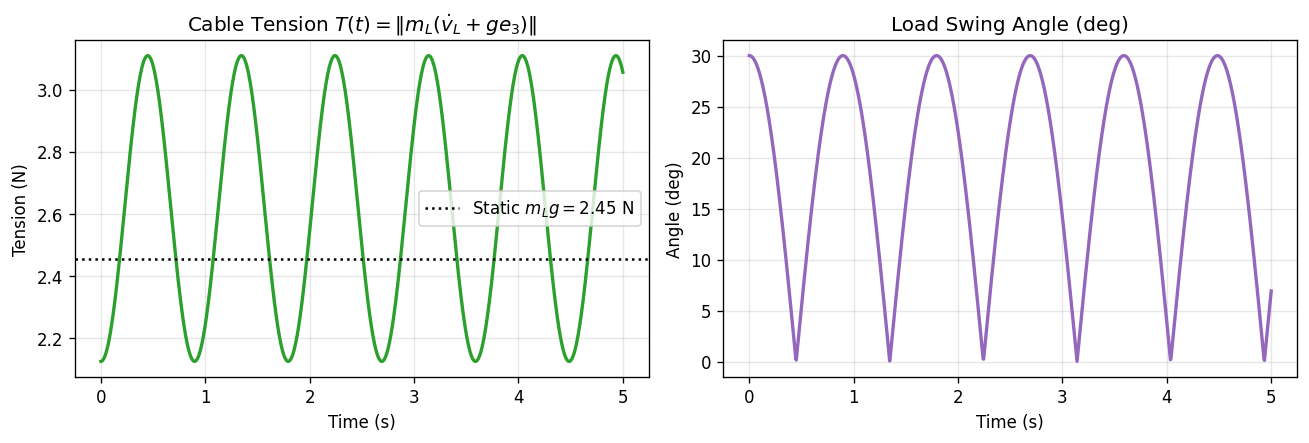

In [5]:
# Test 2: Hover thrust f = (mQ + mL)*g with initial 30-deg load swing
xL = np.array([0.0, 0.0, 2.0])
vL = np.zeros(3)
q = np.array([np.sin(np.pi/6), 0.0, -np.cos(np.pi/6)])
omega = np.zeros(3)
R = np.eye(3)
Omega = np.zeros(3)
f_hover = (mQ + mL) * g

tension_hist = np.zeros(N + 1)
q_z_hist = np.zeros(N + 1)
for k in range(N + 1):
    _, vL_dot, _, _ = rhs_se3_s2(xL, vL, q, omega, R, Omega, f_hover, np.zeros(3))
    tension_hist[k] = mL * np.linalg.norm(vL_dot + g * e3)
    q_z_hist[k] = q[2]
    if k < N:
        xL, vL, q, omega, R, Omega = step_lie_rk4(xL, vL, q, omega, R, Omega, f_hover, np.zeros(3), dt)

print(f"Min Cable Tension (Hover Swing): {np.min(tension_hist):.4f} N (T > 0 => remains taut)")
print(f"Max Cable Tension (Hover Swing): {np.max(tension_hist):.4f} N")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(t_arr, tension_hist, lw=2, color='tab:green')
ax[0].axhline(mL * g, color='k', ls=':', label=f'Static $m_L g = {mL*g:.2f}$ N')
ax[0].set_title('Cable Tension $T(t) = \|m_L(\\dot{v}_L + g e_3)\|$')
ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('Tension (N)')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].plot(t_arr, np.degrees(np.arccos(np.clip(-q_z_hist, -1, 1))), lw=2, color='tab:purple')
ax[1].set_title('Load Swing Angle (deg)')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Angle (deg)')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()